# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Colab Tesla T4. YOLO26n. Данные: [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), CC BY-SA 4.0. Использовал документацию ultralytics и заготовки этого ноутбука. Конвертацию, подсчёт параметров, эвристику и разбор ошибок написал отдельно. Бонусы: 6.2-6.5. В 6.1 своей ручной разметки нет, этот бонус не выполнял.


In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, importlib.metadata, subprocess, sys
if importlib.util.find_spec('ultralytics') is None or importlib.metadata.version('ultralytics') != '8.4.50':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.50'], check=True)

import csv
import hashlib
import json
import math
import os
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics 8.4.50, torch 2.14.1+cu130, device: Tesla T4


In [2]:
FAST_MODE = False
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}
SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 30
BATCH = 8 if FAST_MODE else 16
N_TRAIN_FAST = 64
WORKERS = 0 if os.name == 'nt' else 2
RUN_TIMES = {}
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()


Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'
model_coco = YOLO(WEIGHTS)
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 2**20,
                  params=sum(p.numel() for p in model_coco.model.parameters()), n_classes_coco=len(model_coco.names))
def latency_ms(model, image, device=DEVICE, repeats=20):
    for _ in range(5):
        model.predict(image, imgsz=IMGSZ, device=device, verbose=False, rect=False)
    if device != 'cpu' and torch.cuda.is_available():
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict(image, imgsz=IMGSZ, device=device, verbose=False, rect=False)
    if device != 'cpu' and torch.cuda.is_available():
        torch.cuda.synchronize()
    return (time.perf_counter() - start) * 1000 / repeats
MODEL_INFO['latency_ms'] = latency_ms(model_coco, np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8))


In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.50',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'latency_ms': 11.195784500000627}

**Ответ:** Взял нано: для двух классов и 1000 фото в трейне его достаточно как первого варианта, а на T4 останется время на абляцию. По таблице у n 2.4 млн параметров, COCO mAP50-95 40.9% и 1.7 мс на T4 TensorRT, у s - 9.5 млн, 48.6% и 2.5 мс. Код и веса доступны по AGPL-3.0: при распространении нужно сохранить лицензию и предоставить соответствующий исходный код, а для изменённой сетевой версии предложить его пользователям сервиса.


## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    layers = det_model.model
    n_backbone = len(det_model.yaml['backbone'])
    return {name: sum(p.numel() for layer in part for p in layer.parameters())
            for name, part in [('backbone', layers[:n_backbone]), ('neck', layers[n_backbone:-1]), ('head', layers[-1:])]}

def head_inputs_and_output(det_model, imgsz=640):
    feature_shapes = []
    def hook(module, args):
        feature_shapes.extend(tuple(x.shape) for x in args[0])
    handle = det_model.model[-1].register_forward_pre_hook(hook)
    was_training = det_model.training
    param = next(det_model.parameters())
    try:
        det_model.eval()
        with torch.no_grad():
            out = det_model(torch.zeros(1, 3, imgsz, imgsz, device=param.device, dtype=param.dtype))
    finally:
        handle.remove()
        det_model.train(was_training)
    return feature_shapes, out

def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__


In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'} total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))


[(1, 300, 6), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Ответ:** бекбон выделяет признаки, шея объединяет грубые и детальные карты на масштабах 80*80, 40*40 и 20*20. Голова предсказывает 4 координаты бокса и оценки 80 классов в каждой точке, без заранее заданных anchor-боксов. При входе 640 точек всего 80^2 + 40^2 + 20^2 = 8400. One2many обучается с несколькими положительными предсказаниями на объект и требует NMS. а one2one с одним, поэтому её выход до 300 боксов не требует NMS. В моём выводе есть обе ветки, итоговая форма (1, 300, 6). На бекбон приходится 53.1% параметров, шея - 34.9%, голова - 12.0%


---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
import tarfile
from urllib.request import urlretrieve
DATA_ROOT.mkdir(exist_ok=True)
for name in ['images', 'annotations']:
    if not (DATA_ROOT / name).exists():
        archive = DATA_ROOT / f'{name}.tar.gz'
        if not archive.exists():
            urlretrieve(f'https://thor.robots.ox.ac.uk/datasets/pets/{name}.tar.gz', archive)
        with tarfile.open(archive) as f:
            f.extractall(DATA_ROOT, filter='data')
CLASSES = ['cat_head', 'dog_head']
DATASET_NAME = 'Oxford-IIIT Pet; https://www.robots.ox.ac.uk/~vgg/data/pets/; CC BY-SA 4.0'
pool = [[], []]
cleaning = Counter()
seen_hashes = set()
for xml in sorted((DATA_ROOT / 'annotations/xmls').glob('*.xml')):
    root = ET.parse(xml).getroot()
    image = DATA_ROOT / 'images' / root.findtext('filename')
    with Image.open(image) as im:
        width, height = im.size
    digest = hashlib.sha256(image.read_bytes()).hexdigest()
    if digest in seen_hashes:
        cleaning['duplicate_images'] += 1
        continue
    seen_hashes.add(digest)
    boxes, labels = [], []
    for obj in root.findall('object'):
        b = obj.find('bndbox')
        box = np.array([float(b.findtext(k)) for k in ['xmin', 'ymin', 'xmax', 'ymax']])
        box[:2] -= 1
        clipped = np.clip(box, [0, 0, 0, 0], [width, height, width, height])
        cleaning['clipped'] += int(not np.array_equal(box, clipped))
        if clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
            cleaning['removed'] += 1
            continue
        boxes.append(clipped)
        labels.append({'cat': 0, 'dog': 1}[obj.findtext('name')])
    if labels:
        rec = dict(image=image, width=width, height=height,
                   boxes=np.array(boxes, dtype=np.float32).reshape(-1, 4), labels=np.array(labels, dtype=np.int64))
        pool[labels[0]].append(rec)
records = {'train': [], 'val': []}
rng = np.random.default_rng(SEED)
for items in pool:
    order = rng.permutation(len(items))
    records['train'].extend(items[i] for i in order[:500])
    records['val'].extend(items[i] for i in order[500:625])
print('XML:', sum(len(x) for x in pool), 'очистка:', dict(cleaning))
print({s: len(r) for s, r in records.items()})


XML: 3673 очистка: {'clipped': 0, 'duplicate_images': 13}
{'train': 1000, 'val': 250}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 1000, 'val': 250}

train {'cat_head': 501, 'dog_head': 500} объектов/фото: 1.001
train cat_head медиана w,h: [      0.362       0.417]
train dog_head медиана w,h: [      0.391       0.422]
val {'cat_head': 125, 'dog_head': 125} объектов/фото: 1.0
val cat_head медиана w,h: [       0.38       0.439]
val dog_head медиана w,h: [      0.397       0.439]


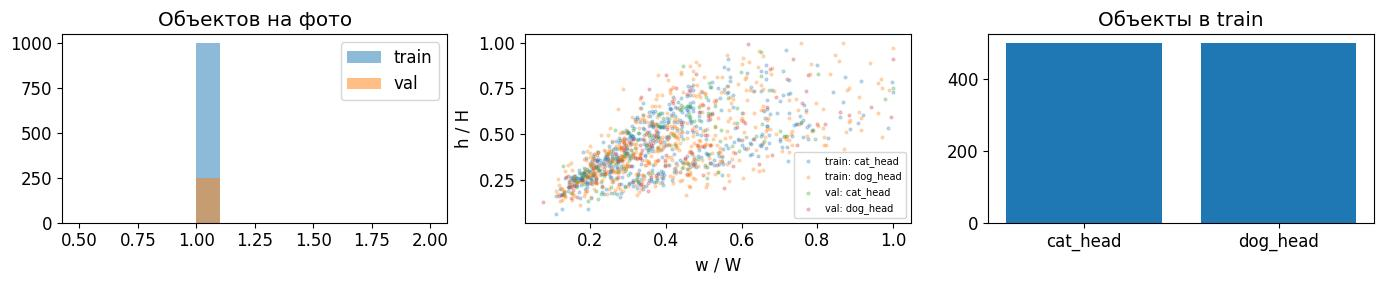

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for split, recs in records.items():
    counts = Counter(int(c) for r in recs for c in r['labels'])
    print(split, {CLASSES[c]: counts[c] for c in range(len(CLASSES))},
          'объектов/фото:', np.mean([len(r['labels']) for r in recs]))
    axes[0].hist([len(r['labels']) for r in recs], alpha=0.5, label=split)
    for c, name in enumerate(CLASSES):
        wh = np.concatenate([(r['boxes'][r['labels'] == c, 2:] - r['boxes'][r['labels'] == c, :2]) /
                             [r['width'], r['height']] for r in recs])
        axes[1].scatter(wh[:, 0], wh[:, 1], s=4, alpha=0.25, label=f'{split}: {name}')
        print(split, name, 'медиана w,h:', np.median(wh, axis=0).round(3))
axes[0].set_title('Объектов на фото'); axes[0].legend()
axes[1].set(xlabel='w / W', ylabel='h / H'); axes[1].legend(fontsize=7)
axes[2].bar(CLASSES, [sum((r['labels'] == c).sum() for r in records['train']) for c in range(2)])
axes[2].set_title('Объекты в train'); plt.tight_layout(); plt.show()


**Ответ:** В Oxford-IIIT Pet 37 пород, но здесь я объединил их в два класса: головы кошек и собак. Из 3686 после удаления 13 дублей осталось 3673 фото. Взял случайные 1000 в train и 250 в val с сидом 0, по 500/125 фото каждого вида. Тест не использовал. В трейне 1001 объект, в валидации 250 и некорректных боксов не нашлось. Медианные ширина и высота головы около 36-40% и 42-44% размера фото, дисбаланса классов нет. Похожие фото одного животного могли попасть в разные сплиты


## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    rows = []
    for box, label in zip(np.asarray(boxes).reshape(-1, 4), labels):
        x1, y1, x2, y2 = box
        coords = [(x1 + x2) / (2 * width), (y1 + y2) / (2 * height), (x2 - x1) / width, (y2 - y1) / height]
        rows.append(str(int(label)) + ' ' + ' '.join(f'{x:.6f}' for x in coords))
    return '\n'.join(rows)

def from_yolo(text, width, height):
    boxes, labels = [], []
    for line in text.splitlines():
        if not line.strip():
            continue
        label, cx, cy, w, h = map(float, line.split())
        boxes.append([(cx - w / 2) * width, (cy - h / 2) * height, (cx + w / 2) * width, (cy + h / 2) * height])
        labels.append(int(label))
    return np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64)


In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    images = YOLO_ROOT / 'images' / split
    labels = YOLO_ROOT / 'labels' / split
    images.mkdir(parents=True, exist_ok=True)
    labels.mkdir(parents=True, exist_ok=True)
    for r in recs:
        image = Path(r['image'])
        shutil.copy2(image, images / image.name)
        (labels / f'{image.stem}.txt').write_text(to_yolo(r['boxes'], r['labels'], r['width'], r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())


path: /content/data/yolo
train: images/train
val: images/val
names:
  0: cat_head
  1: dog_head



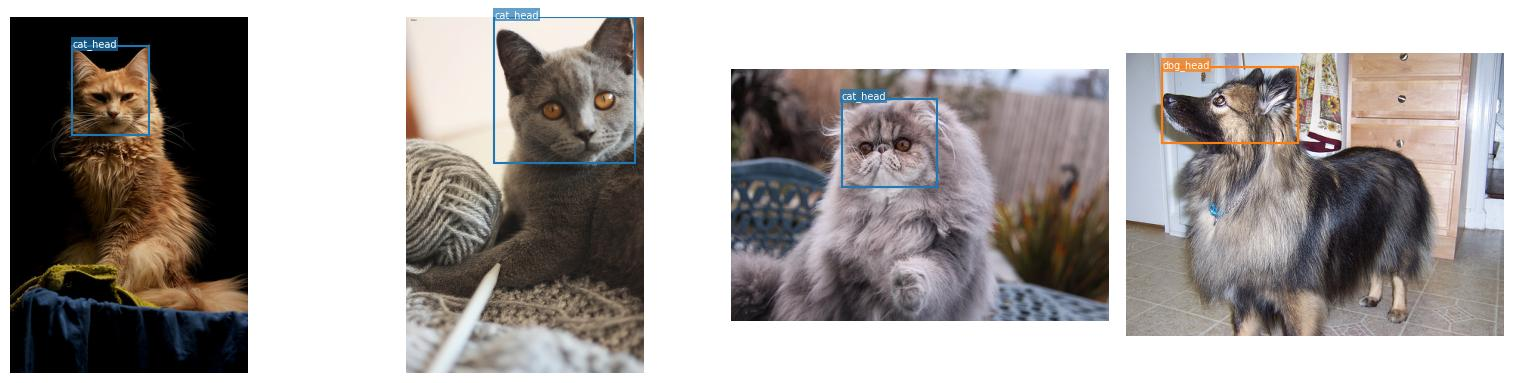

Проверены все экспортированные боксы


In [15]:
for split, recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT / 'labels' / split / (Path(r['image']).stem + '.txt')).read_text()
        b, l = from_yolo(text, r['width'], r['height'])
        assert np.allclose(b, r['boxes'], atol=0.002) and np.array_equal(l, r['labels'])
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, r in zip(axes, records['val'][::max(1, len(records['val']) // 4)][:4]):
    text = (YOLO_ROOT / 'labels/val' / (Path(r['image']).stem + '.txt')).read_text()
    boxes, labels = from_yolo(text, r['width'], r['height'])
    draw_boxes(ax, Image.open(r['image']), boxes, labels, CLASSES)
plt.tight_layout(); plt.show()
print('Проверены все экспортированные боксы')


**Ответ:** Тест проверяет, что после перевода в YOLO и обратно сохранились координаты рамок и классы объектов. Но если голова изначально обведена неправильно, тест этого не заметит. Ещё ошибки в двух функциях могут отменять друг друга: например, первая меняет x и y местами, а вторая меняет их обратно. На картинках проверяем, что рамки попадают на головы, не съехали и имеют нужный размер


---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

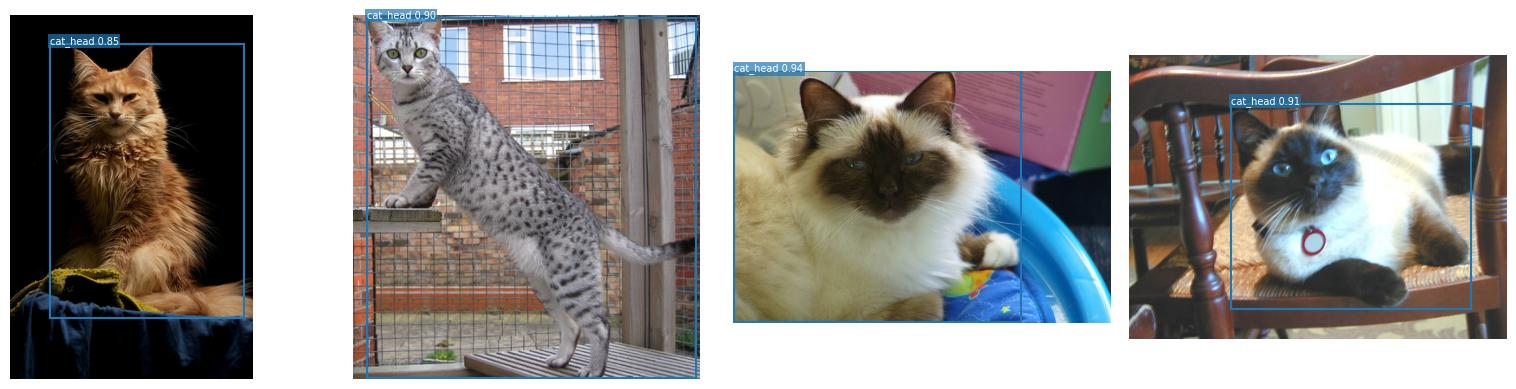

COCO mAP50: 0.04368190477069259 AP50: {'cat_head': 0.02909380336495859, 'dog_head': 0.05827000617642659}


In [16]:
start = time.perf_counter()
coco_raw = predict_records(model_coco, records[FINAL_SPLIT])
coco_preds = []
for p in coco_raw:
    keep = np.isin(p['labels'], [15, 16])
    coco_preds.append(dict(boxes=p['boxes'][keep], scores=p['scores'][keep],
                           labels=np.array([{15: 0, 16: 1}[int(c)] for c in p['labels'][keep]], dtype=np.int64)))
coco_map50, coco_aps = evaluate_map50(coco_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['coco'] = time.perf_counter() - start
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, r, pred in zip(axes, records[FINAL_SPLIT][:4], coco_preds[:4]):
    keep = pred['scores'] >= 0.25
    draw_boxes(ax, Image.open(r['image']), pred['boxes'][keep], pred['labels'][keep], CLASSES, pred['scores'][keep])
plt.tight_layout(); plt.show()
print('COCO mAP50:', coco_map50, 'AP50:', dict(zip(CLASSES, coco_aps)))


In [17]:
def heuristic_detect(image_path):
    with Image.open(image_path) as image:
        width, height = image.size
    boxes, labels, scores = [], [], []
    for c, box in enumerate(mean_boxes):
        for dx, dy in [(0, 0), (-0.1, 0), (0.1, 0), (0, -0.1), (0, 0.1)]:
            b = np.clip(box + [dx, dy, dx, dy], 0, 1) * [width, height, width, height]
            boxes.append(b); labels.append(c); scores.append(0.5 - abs(dx) - abs(dy))
    return dict(boxes=np.array(boxes).reshape(-1, 4), labels=np.array(labels), scores=np.array(scores))


In [18]:
mean_boxes = np.array([np.mean(np.concatenate([r['boxes'][r['labels'] == c] /
                       [r['width'], r['height'], r['width'], r['height']] for r in train_recs]), axis=0)
                       for c in range(len(CLASSES))])
print(mean_boxes)


[[    0.30874      0.1259     0.70136     0.56322]
 [     0.2775     0.15499      0.6982     0.60685]]


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'val',
 'coco_map50': 0.04368190477069259,
 'heuristic_map50': 0.05378373757215374,
 'heuristic_ap50_per_class': {'cat_head': 0.07094512144655828,
  'dog_head': 0.036622353697749195}}

**Ответ:** У COCO-модели mAP50 4.37%: кошек и собак она знает, но обычно выделяет всё животное, а здесь нужна только голова. У эвристики 5.38%, по кошкам 7.09%, по собакам 3.66%. Средний бокс иногда попадает на крупную голову около центра кадра, но не умеет подстроиться под её положение и размер + у собак добавляется разнообразие формы морды. Дообучению нужно научить именно границы головы


---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, optimizer='AdamW', lr0=0.001,
                  lrf=0.01, weight_decay=0.0005, warmup_epochs=2, patience=10, seed=SEED,
                  deterministic=True, val=True, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4,
                  degrees=10, translate=0.1, scale=0.3, fliplr=0.5, flipud=0.0,
                  mosaic=0.5, close_mosaic=5, mixup=0.0, plots=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=6

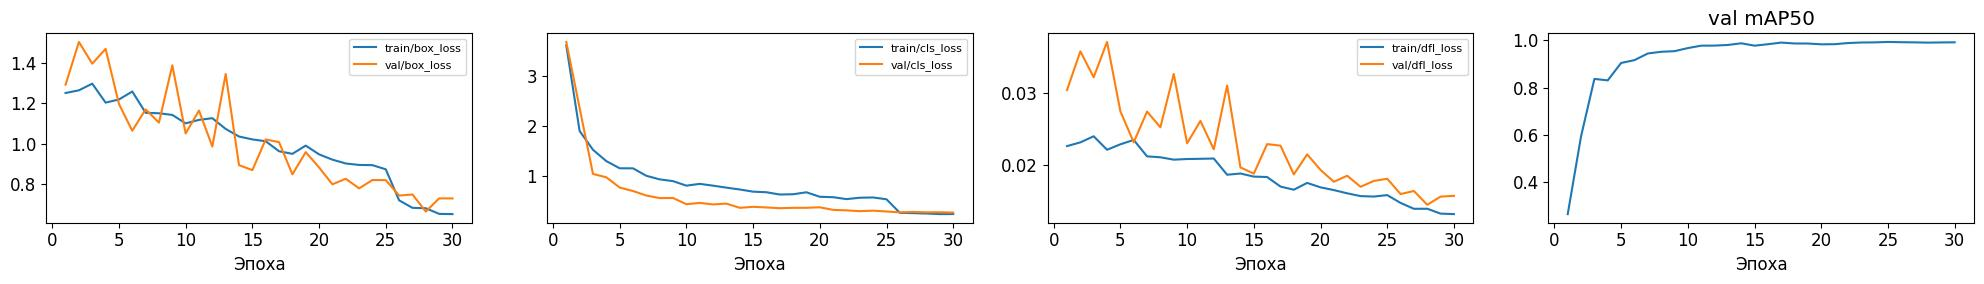

{'train/box_loss': (1.2502, 0.65057), 'train/cls_loss': (3.60339, 0.23335), 'train/dfl_loss': (0.02257, 0.01309), 'metrics/mAP50(B)': (0.26578, 0.99208), 'metrics/mAP50-95(B)': (0.15502, 0.81359), 'val/box_loss': (1.29125, 0.7282), 'val/cls_loss': (3.67231, 0.26219), 'val/dfl_loss': (0.03038, 0.01564)}


In [23]:
curves = read_results(run_dir)
loss_keys = [k for k in curves if k.startswith('train/') and k.endswith('loss')]
fig, axes = plt.subplots(1, len(loss_keys) + 1, figsize=(5 * (len(loss_keys) + 1), 3))
for ax, key in zip(axes, loss_keys):
    ax.plot(curves['epoch'], curves[key], label=key)
    other = key.replace('train/', 'val/')
    if other in curves:
        ax.plot(curves['epoch'], curves[other], label=other)
    ax.legend(fontsize=8); ax.set_xlabel('Эпоха')
axes[-1].plot(curves['epoch'], curves['metrics/mAP50(B)'])
axes[-1].set(xlabel='Эпоха', title='val mAP50'); plt.tight_layout(); plt.show()
print({k: (float(v[0]), float(v[-1])) for k, v in curves.items() if 'loss' in k or 'mAP' in k})


**Ответ:** Взял 640, чтобы не терять детали границы головы, batch 16 помещается в T4. AdamW с lr=0.001 и warmup 2 эпохи - спокойное дообучение. Аугментация: горизонтальные отражения, небольшие повороты и изменения цвета. За 30 эпох боксовый трейн лосс снизился с 1.250 до 0.651, а на валидации с 1.291 до 0.728. Классовый лосс тоже упал на обоих сплитах, явного роста val лосса при падении трейна нет. В конце метрика ещё улучшалась, так что 30 эпох хватило для хорошего результата, но не факт что прям сошлось


## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [24]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1030.5±680.6 MB/s, size: 46.7 KB)
val: /content/data/yolo/images/val/Egyptian_Mau_138.jpg: corrupt JPEG restored and saved
                   all        250        250      0.964      0.963      0.991      0.826
Speed: 3.2ms preprocess, 5.3ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs_hw2/final_val
{
  "map50": 0.9912111656522573,
  "map50_95": 0.8258431350592297,
  "precision": 0.9640167214751729,
  "recall": 0.9629579984764083,
  "per_class": {
    "cat_head": {
      "precision": 0.9605842163112327,
      "recall": 0.9748298070597524,
      "map50": 0.9923430483554349,
      "map50_95": 0.8696409159412377
    },
    "dog_head": {
      "precision": 0.9674492266391131,
      "recall": 0.951086189893064,
      "map50": 0.9900792829490

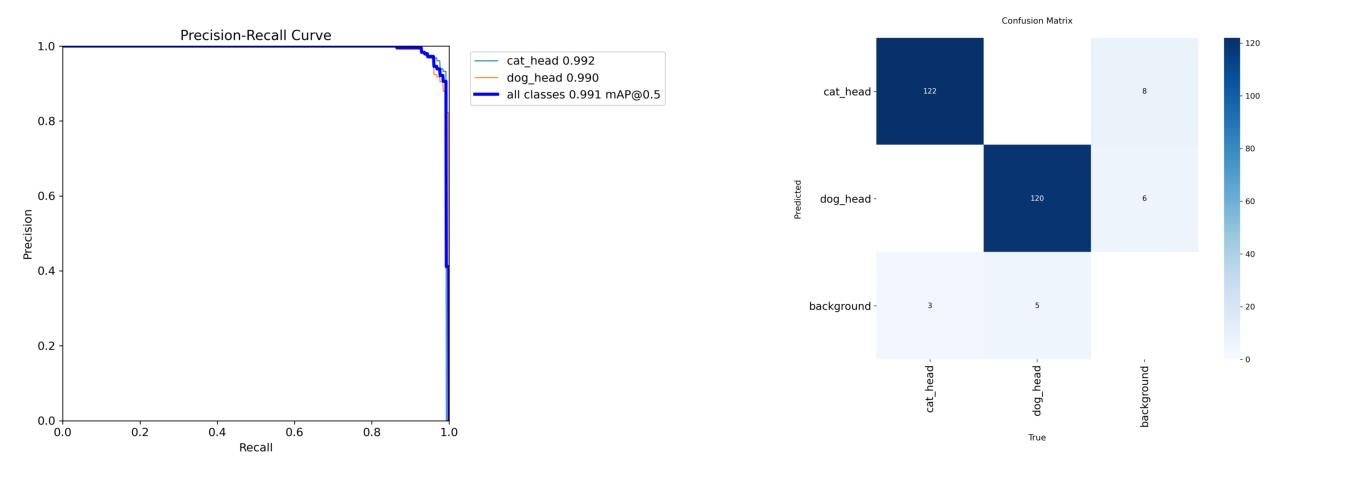

In [25]:
def pack_metrics(m):
    b = m.box
    return dict(map50=float(b.map50), map50_95=float(b.map), precision=float(b.mp), recall=float(b.mr),
                per_class={CLASSES[int(c)]: dict(precision=float(b.p[i]), recall=float(b.r[i]),
                    map50=float(b.ap50[i]), map50_95=float(b.ap[i])) for i, c in enumerate(b.ap_class_index)})
validation = {s: val_metrics(best, s, f'final_{s}', plots=True, conf=0.001) for s in records if s != 'train'}
FINAL = pack_metrics(validation[FINAL_SPLIT])
final_preds = predict_records(best, records[FINAL_SPLIT])
custom_map50, custom_aps = evaluate_map50(final_preds, records[FINAL_SPLIT], len(CLASSES))
print(json.dumps(FINAL, indent=2)); print('свой mAP50:', custom_map50)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, filename in zip(axes, ['BoxPR_curve.png', 'confusion_matrix.png']):
    ax.imshow(plt.imread(validation[FINAL_SPLIT].save_dir / filename)); ax.axis('off')
plt.tight_layout(); plt.show()


In [26]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.9912, 'map50_95': 0.8258, 'precision': 0.964, 'recall': 0.963}

**Ответ:** Получилось mAP50 99.12%, mAP50-95 82.58%, precision 96.40%, recall 96.30%. У собак AP50-95 78.20% против 86.96% у кошек: примеров поровну, но форма головы и ракурсы у собак разнообразнее. В confusion matrix строки это предсказания, а столбцы это разметка: строка background показывает пропуски, а столбец лишние детекции. На IoU неточная граница головы уже считается ошибкой, поэтому mAP50-95 ниже. Свой mAP50 99.45%, выше ultralytics: отличаются интерполяция PR-кривой, сопоставление боксов и паддинг при предикте и валидации.


---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [27]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')
def box_iou_np(a, b):
    a, b = np.asarray(a).reshape(-1, 4), np.asarray(b).reshape(-1, 4)
    inter = np.maximum(0, np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2])).prod(-1)
    area_a = np.maximum(0, a[:, 2:] - a[:, :2]).prod(-1)
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(-1)
    union = area_a[:, None] + area_b[None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter, dtype=float), where=union > 0)

def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    ious = box_iou_np(pred['boxes'], gt['boxes'])
    found, linked = set(), set()
    cats = ['background'] * len(pred['boxes'])
    gt_labels = np.asarray(gt['labels'])
    for i in np.argsort(-np.asarray(pred['scores']), kind='stable'):
        same = gt_labels == pred['labels'][i]
        unused = np.array([j not in found for j in range(len(gt_labels))], dtype=bool)
        candidates = [np.flatnonzero(same & unused & (ious[i] >= iou_hit)),
                      np.flatnonzero(~same & (ious[i] >= iou_hit)),
                      np.flatnonzero(same & unused & (ious[i] >= iou_loc) & (ious[i] < iou_hit))]
        for category, ids in zip(['tp', 'class', 'localization'], candidates):
            if len(ids):
                j = int(ids[np.argmax(ious[i, ids])])
                cats[i] = category
                linked.add(j)
                if category == 'tp':
                    found.add(j)
                break
    return cats, [j for j in range(len(gt_labels)) if j not in linked]


In [28]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


{'tp': 246, 'class': 2, 'localization': 0, 'background': 8, 'missed': 3}
доли: {'tp': 0.95, 'class': 0.008, 'localization': 0.0, 'background': 0.031, 'missed': 0.012}
{'cat_head': {'tp': 122, 'class': 1, 'localization': 0, 'background': 5, 'missed': 2}, 'dog_head': {'tp': 124, 'class': 1, 'localization': 0, 'background': 3, 'missed': 1}}


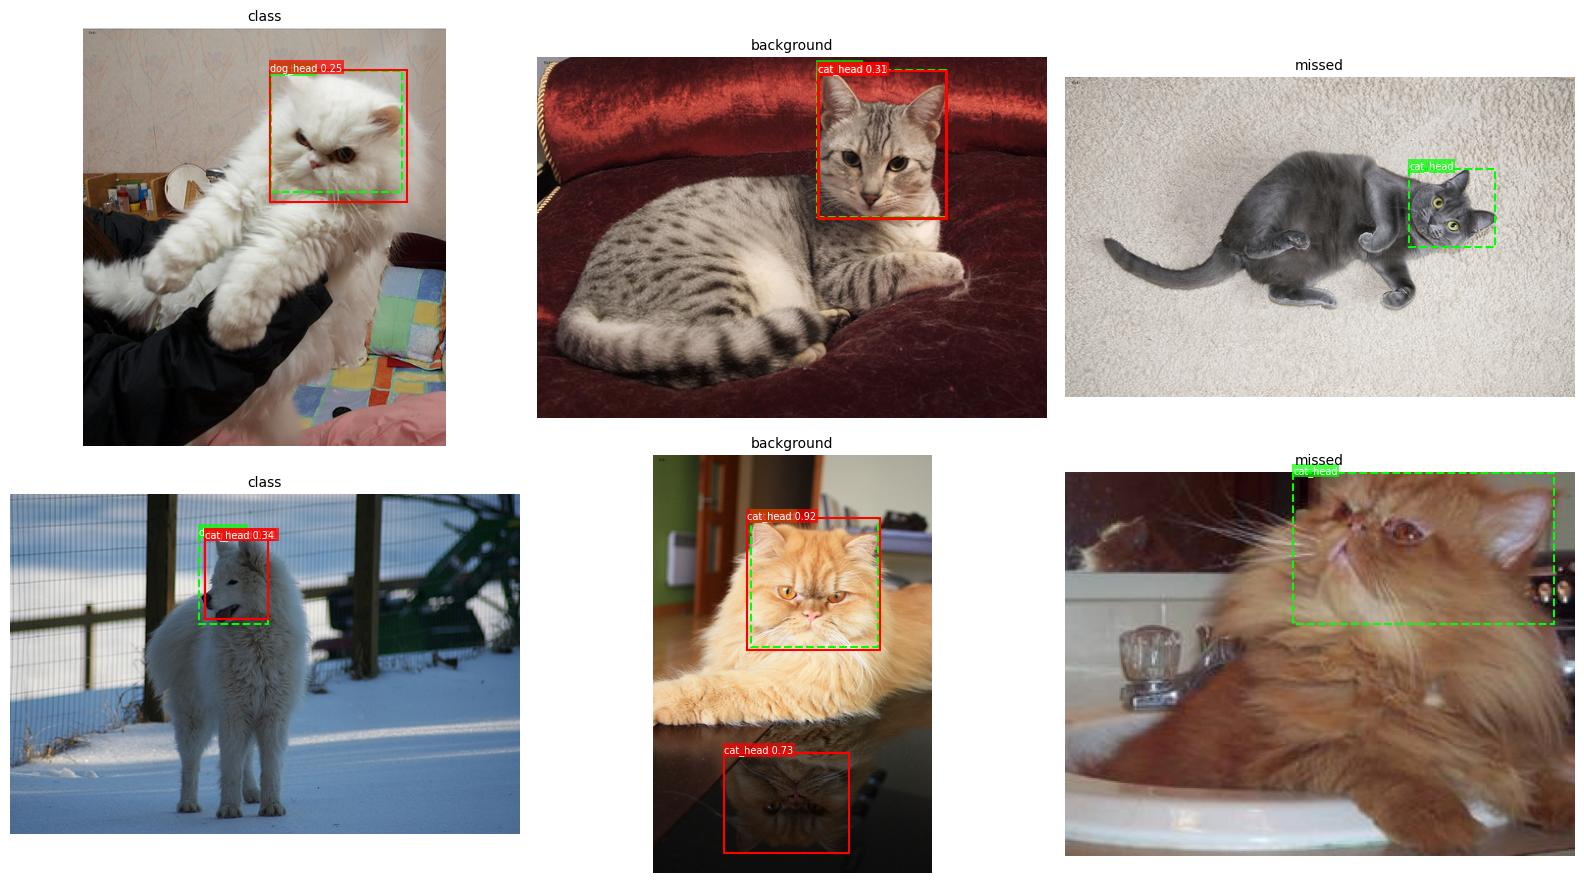

In [29]:
val_preds = final_preds if FINAL_SPLIT == 'val' else predict_records(best, records['val'])
ERRORS = dict.fromkeys(ERROR_TYPES, 0)
errors_by_class = {c: dict.fromkeys(ERROR_TYPES, 0) for c in CLASSES}
error_examples = {c: [] for c in ERROR_TYPES if c != 'tp'}
for r, p in zip(records['val'], val_preds):
    keep = p['scores'] >= CONF_ERRORS
    pred = {k: v[keep] for k, v in p.items()}
    cats, missed = categorize_predictions(pred, r)
    for cat, label in zip(cats, pred['labels']):
        ERRORS[cat] += 1
        errors_by_class[CLASSES[int(label)]][cat] += 1
    ERRORS['missed'] += len(missed)
    for j in missed:
        errors_by_class[CLASSES[int(r['labels'][j])]]['missed'] += 1
    for category in error_examples:
        if category in cats or (category == 'missed' and missed):
            error_examples[category].append((r, pred, category))
print(ERRORS)
print('доли:', {k: round(v / max(sum(ERRORS.values()), 1), 3) for k, v in ERRORS.items()})
print(errors_by_class)
examples = []
for j in range(6):
    for items in error_examples.values():
        if j < len(items):
            examples.append(items[j])
examples = examples[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (r, pred, category) in zip(axes.flat, examples):
    draw_boxes(ax, Image.open(r['image']), r['boxes'], r['labels'], CLASSES, color='lime', linestyle='--')
    draw_boxes(ax, None, pred['boxes'], pred['labels'], CLASSES, pred['scores'], color='red', title=category)
for ax in list(axes.flat)[len(examples):]:
    ax.axis('off')
plt.tight_layout(); plt.show()


**Ответ:** Главная категория - лишние боксы: 8 из 13 ошибок. На примерах есть дубли и отражение кошки без разметки, так что не все FP это ошибка распознавания. Ещё модель путает плоскую морду кошки с собакой и белую собаку с кошкой, пропускает повёрнутые и размытые головы. Сначала проверил бы разметку и правило для отражений, потом добавил фоновые и сложные примеры. Дубли можно уменьшить через NMS или более высокий порог уверенности


## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [30]:
ablation_args = {**TRAIN_ARGS, 'imgsz': 320 if IMGSZ == 640 else 640}
ab_model, ab_time, ab_dir = train_yolo('ablation_imgsz', **ablation_args)
ab_best = YOLO(ab_dir / 'weights/best.pt')
ab_val = ab_best.val(data=str(DATA_YAML), split='val', imgsz=ablation_args['imgsz'], batch=BATCH,
                     device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name='ablation_val', verbose=False)
ABLATION = dict(parameter='imgsz', variants=[dict(value=IMGSZ, **pack_metrics(validation['val']), train_time_sec=RUN_TIMES['train']),
                                           dict(value=ablation_args['imgsz'], **pack_metrics(ab_val), train_time_sec=ab_time)])
print(json.dumps(ABLATION, indent=2))


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=320, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=ablation_imgsz,

**Ответ:** На 320 получилось 97.85% mAP50 и 76.55% mAP50-95 против 99.12% и 82.58% на 640. Обучение сократилось с 626 до 443 с, то есть почти в 1.5 раза, но потеря по метрике 6%. На меньшей картинке труднее точно провести границы головы. Для этого небольшого датасета я бы оставил 640, дополнительные три минуты оправданы качеством


## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** После дообучения mAP50 вырос с 4.37% до 99.12%: модель научилась выделять головы, а не животных целиком. Рамки со средними размерами и положением дали только 5.38%, потому что на каждом фото голова находится в своём месте. Если строже проверять, насколько точно рамка обводит голову, результат ниже: mAP50-95 82.58%, у собак 78.20%. При conf=0.25 модель поставила 8 лишних рамок, 2 раза перепутала кошку с собакой и пропустила 3 головы. На размере 320 обучение шло почти в 1.5 раза быстрее, но mAP50-95 упал с примерно на 6%, поэтому я бы оставил 640. Проверка была только на 250 фото, а обучение запускалось один раз с одним сидом, поэтому на других данных результат может отличаться. Похожие фото могли попасть и в обучение, и в проверку, а в разметке есть спорные случаи, например голова кошки в отражении без рамкиы. Дальше я бы проверил модель на новых фото, в том числе без животных и добавил в обучение больше сложных примеров.


### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [31]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['best.pt', 'metrics.json', 'results.csv']


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [32]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Откажусь пожалуй) Слишком много уже было мною размечено


## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [33]:
if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR
    transformer = RTDETR('rtdetr-l.pt')
    rt_args = {**TRAIN_ARGS, 'epochs': 2 if FAST_MODE else 20, 'batch': 4, 'mosaic': 0.0, 'close_mosaic': 0}
    start = time.perf_counter()
    transformer.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()),
                      name='rtdetr', exist_ok=True, verbose=False, **rt_args)
    RUN_TIMES['rtdetr'] = time.perf_counter() - start
    rt_dir = Path(transformer.trainer.save_dir)
    transformer = RTDETR(rt_dir / 'weights/best.pt')
    rtdetr_params = sum(p.numel() for p in transformer.model.parameters())
    rt_val = val_metrics(transformer, 'val', 'rtdetr_val')
    speed_image = np.asarray(Image.open(records['val'][0]['image']).convert('RGB'))[:, :, ::-1].copy()
    RTDETR_RESULT = dict(**pack_metrics(rt_val), params=rtdetr_params, train_time_sec=RUN_TIMES['rtdetr'],
                         latency_ms=latency_ms(transformer, speed_image), epochs=rt_args['epochs'])
    YOLO_SPEED = latency_ms(best, speed_image)
    print('YOLO:', dict(params=sum(p.numel() for p in YOLO(run_dir / 'weights/best.pt').model.parameters()), latency_ms=YOLO_SPEED))
    print('RT-DETR:', RTDETR_RESULT)


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=10, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=rtdetr, nbs=64,

**Ответ:** RT-DETR дал mAP50 96% и mAP50-95 67%, YOLO 99% и 83%. RT-DETR тяжелее: около 33 млн параметров против 2.5 млн, обучение 2736 с против 626 с, задержка 44 мс против 13 мс на T4 при входе 640 на 640 и batch=1. Recall чуть выше: 97.8% против 96.3%, но precision ниже: 91.5% против 96.4%. Здесь выбрал бы YOLO. RT-DETR попробовал бы при большем наборе данных и бюджете, если бы он лучше находил сложные объекты.


## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

In [13]:
if '6.3' in BONUS_TASKS:
    SHIFT_RESULTS = {}
    rng = np.random.default_rng(SEED)
    for corruption in ['dark', 'noise', 'jpeg']:
        shifted_root = DATA_ROOT / f'shift_{corruption}'
        (shifted_root / 'images/val').mkdir(parents=True, exist_ok=True)
        (shifted_root / 'labels/val').mkdir(parents=True, exist_ok=True)
        for r in records['val']:
            image = Image.open(r['image']).convert('RGB')
            array = np.array(image).astype(float)
            if corruption == 'dark':
                image = Image.fromarray((array * 0.3).astype(np.uint8))
            elif corruption == 'noise':
                image = Image.fromarray(np.clip(array + rng.normal(0, 35, array.shape), 0, 255).astype(np.uint8))
            image.save(shifted_root / 'images/val' / Path(r['image']).name, quality=8 if corruption == 'jpeg' else 95)
            shutil.copy2(YOLO_ROOT / 'labels/val' / (Path(r['image']).stem + '.txt'), shifted_root / 'labels/val')
        config = shifted_root / 'data.yaml'
        config.write_text(f'path: {shifted_root.resolve()}\ntrain: images/val\nval: images/val\nnames: {CLASSES}\n')
        m = best.val(data=str(config), imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=f'shift_{corruption}', exist_ok=True, verbose=False)
        SHIFT_RESULTS[corruption] = pack_metrics(m)
    print(json.dumps(SHIFT_RESULTS, indent=2))


Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1313.0±341.3 MB/s, size: 34.8 KB)
val: New cache created: /content/data/shift_dark/labels/val.cache
                   all        250        250      0.967      0.949      0.988      0.812
Speed: 2.9ms preprocess, 4.2ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/runs_hw2/shift_dark
Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2552.1±1179.2 MB/s, size: 127.6 KB)
val: New cache created: /content/data/shift_noise/labels/val.cache
                   all        250        250      0.803      0.435      0.548      0.375
Speed: 2.1ms preprocess, 3.5ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /content/runs_hw2/shift_noise
Ultralytics 8

**Ответ:** На исходных фото mAP50 / mAP50-95 - 99.1% / 82.6%. После затемнения до 30% исходной яркости качество почти не изменилось: 98.8% / 81.2%. Сильный случайный шум снизил результат до 54.8% / 37.5%, а сильное jpeg-сжатие до 24% / 15.3%. Хуже всего модель справилась со сжатыми фото, особенно с собаками: AP50 15.2% против 32.9% у кошек. Я бы добавил в обучение фото с разной силой шума и сжатия, чтобы модель привыкла к таким искажениям, а потом проверил её на реальных фото плохого качества. Затемнённые и зашумлённые фото тоже сохранялись в jpeg, но с высоким качеством 95, поэтому часть изменений могла быть связана с повторным сохранением


## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [14]:
if '6.4' in BONUS_TASKS:
    for package in ['onnx', 'onnxruntime']:
        if importlib.util.find_spec(package) is None:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', package], check=True)
    cpu_best = YOLO(run_dir / 'weights/best.pt')
    onnx_path = cpu_best.export(format='onnx', imgsz=IMGSZ, device='cpu', simplify=False, opset=17)
    shutil.copy2(onnx_path, artifact_dir / 'best.onnx')
    onnx_model = YOLO(onnx_path, task='detect')
    cpu_image = np.asarray(Image.open(records['val'][0]['image']).convert('RGB'))[:, :, ::-1].copy()
    torch.set_num_threads(2)
    import onnxruntime as ort
    session_options = ort.SessionOptions()
    session_options.intra_op_num_threads = 2
    session_options.inter_op_num_threads = 1
    original_session = ort.InferenceSession
    def limited_session(*args, **kw):
        kw['sess_options'] = session_options
        return original_session(*args, **kw)
    ort.InferenceSession = limited_session
    try:
        torch_ms = latency_ms(cpu_best, cpu_image, device='cpu')
        onnx_ms = latency_ms(onnx_model, cpu_image, device='cpu')
        pytorch_val = cpu_best.val(data=str(DATA_YAML), imgsz=IMGSZ, batch=1, rect=False, device='cpu', workers=WORKERS,
                                    project=str(RUNS.resolve()), name='pytorch_cpu_val', verbose=False)
        onnx_val = onnx_model.val(data=str(DATA_YAML), imgsz=IMGSZ, batch=1, rect=False, device='cpu', workers=WORKERS,
                                  project=str(RUNS.resolve()), name='onnx_val', verbose=False)
        EXPORT_RESULT = dict(pytorch_ms=torch_ms, onnx_ms=onnx_ms, speedup=torch_ms / onnx_ms,
                              pytorch_metrics=pack_metrics(pytorch_val), device='Colab CPU; 2 threads; FP32; batch=1; preprocess + inference + postprocess',
                              **pack_metrics(onnx_val))
    finally:
        ort.InferenceSession = original_session
    print(EXPORT_RESULT)


{'pytorch_ms': 109.66054850000546, 'onnx_ms': 77.55993449995913, 'speedup': 1.4138813964581578, 'device': 'Colab CPU; 2 threads; FP32; batch=1; preprocess + inference + postprocess', 'map50': 0.9933512551581165, 'map50_95': 0.8041467914623631, 'precision': 0.9796375054525689, 'recall': 0.972, 'per_class': {'cat_head': {'precision': 0.9773333766148411, 'recall': 0.968, 'map50': 0.992828110418673, 'map50_95': 0.8528270614888369}, 'dog_head': {'precision': 0.9819416342902967, 'recall': 0.976, 'map50': 0.9938743998975601, 'map50_95': 0.7554665214358897}}, 'pytorch_metrics': {'map50': 0.9933512551581165, 'map50_95': 0.8041467914623631, 'precision': 0.9796374472021405, 'recall': 0.972, 'per_class': {'cat_head': {'precision': 0.9773334526033186, 'recall': 0.968, 'map50': 0.992828110418673, 'map50_95': 0.8528270614888369}, 'dog_head': {'precision': 0.9819414418009623, 'recall': 0.976, 'map50': 0.9938743998975601, 'map50_95': 0.7554665214358897}}}}


**Ответ:** ONNX ускорил обработку на CPU Colab с двумя потоками примерно в 1.5 раза: 109.66 -> 77.56 мс на фото. В обоих случаях FP32, batch=1, вход 640 на 640, 5 прогревов и 20 замеров. Я учитывал подготовку изображения, инференс и обработку выхода. ONNX Runtime оптимизирует граф и выполнение операций. При одинаковой валидации (CPU, batch=1, rect=False) mAP50 совпал и mAP50-95 тоже. Потери качества от экспорта не видно

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [15]:
if '6.5' in BONUS_TASKS:
    THRESHOLD_RESULTS = []
    for end2end in [True, False]:
        for conf in [0.001, 0.1, 0.25, 0.5]:
            for iou in [0.3, 0.7]:
                candidate = YOLO(run_dir / 'weights/best.pt')
                m = candidate.val(data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                                  workers=WORKERS, conf=conf, iou=iou, end2end=end2end, plots=False,
                                  project=str(RUNS.resolve()), name=f'threshold_{end2end}_{conf}_{iou}', verbose=False)
                preds = predict_records(candidate, records['val'], conf=conf, iou=iou, end2end=end2end)
                tp = fp = fn = 0
                for pred, gt in zip(preds, records['val']):
                    cats, _ = categorize_predictions(pred, gt)
                    hits = cats.count('tp')
                    tp += hits; fp += len(cats) - hits; fn += len(gt['boxes']) - hits
                row = dict(end2end=end2end, conf=conf, iou=iou, **pack_metrics(m),
                           precision_at_conf=tp / max(tp + fp, 1), recall_at_conf=tp / max(tp + fn, 1))
                THRESHOLD_RESULTS.append(row)
                print({k: v for k, v in row.items() if k != 'per_class'})
    (artifact_dir / 'bonus_metrics.json').write_text(json.dumps(json_ready(dict(
        rtdetr=globals().get('RTDETR_RESULT'), shift=globals().get('SHIFT_RESULTS'),
        export=globals().get('EXPORT_RESULT'), thresholds=THRESHOLD_RESULTS)), indent=2, allow_nan=False))


Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1867.2±927.9 MB/s, size: 70.8 KB)
val: /content/data/yolo/images/val/Egyptian_Mau_138.jpg: corrupt JPEG restored and saved
                   all        250        250      0.964      0.963      0.991      0.826
Speed: 0.9ms preprocess, 3.4ms inference, 0.0ms loss, 0.3ms postprocess per image
{'end2end': True, 'conf': 0.001, 'iou': 0.3, 'map50': 0.9912111656522573, 'map50_95': 0.8258431350592297, 'precision': 0.9640167214751729, 'recall': 0.9629579984764083, 'precision_at_conf': 0.3733133433283358, 'recall_at_conf': 0.996}
Ultralytics 8.4.50 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,226 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1853.4±1149.9 MB/s, size: 72.1 KB)
val:

**Ответ:** Для e2e оставил бы conf=0.25: precision 96.09%, recall 98.4% по предсказаниям при этом пороге. При conf=0.1 получается 91.21% / 99.6%, при 0.5 - 99.58% / 94.8%: выбор зависит от того, че нам дороже - лишний бокс или пропуск. mAP считается по PR-кривой, поэтому удаление самых слабых детекций влияет мало. Но высокий порог уже обрезает recall: при 0.25 mAP50 96.37%, при 0.5 - 91.46%. В e2e iou=0.3 и 0.7 дали одинаковые результаты, потому что NMS нет. С e2e=False порог NMS работает: при conf=0.25 precision 98.81% / 98.03% для iou=0.3 / 0.7, recall 99.60% в обоих случаях
